In [78]:
import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
from sklearn.metrics import auc

%matplotlib inline

In [79]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
if not os.path.exists("course_lead_scoring_2026"):
    !wget $data


--2026-10-19 19:24:07--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.108.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv’

course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.001s  

2026-10-19 19:24:07 (182 MB/s) - ‘course_lead_scoring_2026.csv’ saved [278746/278746]



In [80]:
# DATA PREPARATION
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')
df.head()    

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [81]:
df.head().T



,0,1,2,3,4
lead_source,organic_search,social_media,referral,paid_ads,referral
industry,technology,technology,retail,manufacturing,manufacturing
employment_status,employed,employed,employed,student,student
location,europe,south_america,europe,NaN,north_america
annual_income,88160.0,72688.0,44697.0,NaN,24062.0
number_of_courses_viewed,3,3,3,3,4
interaction_count,4,7,4,6,5
lead_score,0.64,0.72,0.58,0.57,0.62
converted,1,1,1,0,1


In [82]:
# Missing values
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [83]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [84]:
# Categorical features get 0.0
fill_values = {
    # Categorical features get 'NA'
    "lead_source": "NA",
    "industry": "NA",
    "employment_status": "NA",
    "location": "NA",
}

df.fillna(value=fill_values, inplace=True)
df.isnull().sum()


lead_source                   0
industry                      0
employment_status             0
location                      0
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [85]:
# Numerical features get 0.0
fill_values = {
    "annual_income": 0.0,
    "number_of_courses_viewed": 0.0,
    "interaction_count": 0.0,
    "lead_score": 0.0,
    "converted": 0.0,
}
df.fillna(value=fill_values, inplace=True)
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [86]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [87]:
len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

Question 1: ROC AUC feature importance

,feat,auc
0,lead_score,0.788225
1,interaction_count,0.764920
2,number_of_courses_viewed,0.722989
3,annual_income,0.608198


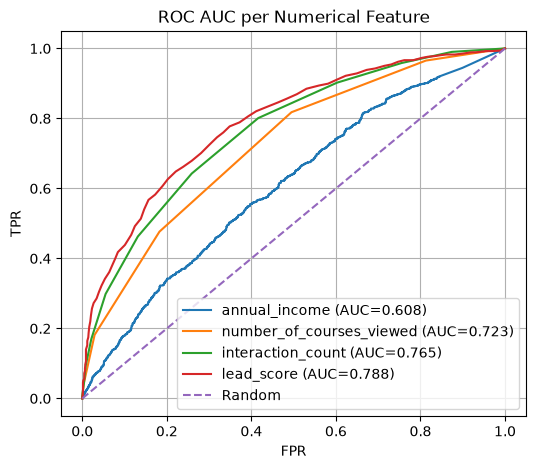

In [88]:

numerical = [
    'annual_income',
    'number_of_courses_viewed',
    'interaction_count',
    'lead_score'
]

result_list = []
plt.figure(figsize=(6, 5))

for c in numerical:
    fpr, tpr, thresholds = roc_curve(df_train['converted'], df_train[c])
    auc_score = auc(fpr, tpr)

    if auc_score < 0.5:
        fpr, tpr, thresholds = roc_curve(df_train['converted'], -df_train[c])
        auc_score = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f'{c} (AUC={auc_score:.3f})')
    result_list.append([c, auc_score])

df_auc_scores = pd.DataFrame(result_list, columns=['feat', 'auc'])
df_auc_scores = df_auc_scores.sort_values(
    by='auc', ascending=False
).reset_index(drop=True)

display(df_auc_scores)

plt.plot([0, 1], [0, 1], linestyle='--', label='Random')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC AUC per Numerical Feature')
plt.legend()
plt.grid(True)
plt.show()



In [89]:
print("Feature with highest AUC:", df_auc_scores.iloc[0]['feat'])
print("Highest AUC:", round(df_auc_scores.iloc[0]['auc'], 4))

Feature with highest AUC: lead_score
Highest AUC: 0.7882


Question 2: Training the model

In [90]:

def train(df_train, y_train, feat_list, C=1.0, max_iter=1000):
    dicts = df_train[feat_list].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=max_iter)
    model.fit(X_train, y_train)
    
    return dv, model

def predict(df, dv, model, feat_list):
    dicts = df[feat_list].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [91]:
feat_list = list(df_train.columns)
feat_list.remove('converted')

dv, model = train(df_train, df_train.converted, feat_list=feat_list)

In [92]:
y_pred = predict(df_val, dv, model, feat_list=feat_list)
y_pred

array([0.54472295, 0.79005191, 0.50977882, 0.52913934, 0.82072017,
       0.54245972, 0.50178712, 0.54698383, 0.82553291, 0.40583727,
       0.91301561, 0.33581811, 0.3078986 , 0.42704772, 0.62192275,
       0.53665458, 0.41931913, 0.84087339, 0.79969125, 0.61790114,
       0.61625177, 0.68059912, 0.85605897, 0.80784865, 0.62045997,
       0.45970701, 0.54556694, 0.41221371, 0.72714005, 0.46812072,
       0.77222173, 0.79043872, 0.61433884, 0.78549743, 0.49753403,
       0.66077266, 0.69804748, 0.7689654 , 0.65657485, 0.64127885,
       0.66509096, 0.57942799, 0.67830929, 0.61186087, 0.86890227,
       0.41469665, 0.84130122, 0.74229349, 0.68028533, 0.71891426,
       0.86417924, 0.64043347, 0.54246978, 0.70225148, 0.27894882,
       0.70826471, 0.62310687, 0.47781739, 0.37914002, 0.69936026,
       0.52032849, 0.69977687, 0.75148933, 0.58087478, 0.47001782,
       0.56863462, 0.91297177, 0.79972016, 0.82206537, 0.36140182,
       0.66132377, 0.52330037, 0.79295454, 0.72068061, 0.71234

In [93]:
round(roc_auc_score(df_val.converted, y_pred), 3)

0.732

Question 3: Precision and Recall

In [94]:
pr_results = list()
thresholds = np.linspace(0,1,100)
for thr in thresholds:
    actual_positive = (df_val.converted == 1)
    actual_negative = (df_val.converted == 0)
    
    predict_positive = (y_pred >= thr)
    predict_negative = (y_pred < thr)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    #print([thr, tp, tn, fp, fn])
    
    pr_results.append([thr, tp, tn, fp, fn])

df_pr = pd.DataFrame(pr_results, columns=["thr", "tp", "tn", "fp", "fn"])
df_pr.head()

,thr,tp,tn,fp,fn
0,0.000000,586,0,414,0
1,0.010101,586,0,414,0
2,0.020202,586,0,414,0
3,0.030303,586,0,414,0
4,0.040404,586,0,414,0


In [95]:
df_pr["precision"] = df_pr.tp / (df_pr.tp + df_pr.fp)
df_pr["recall"] = df_pr.tp / (df_pr.tp + df_pr.fn)

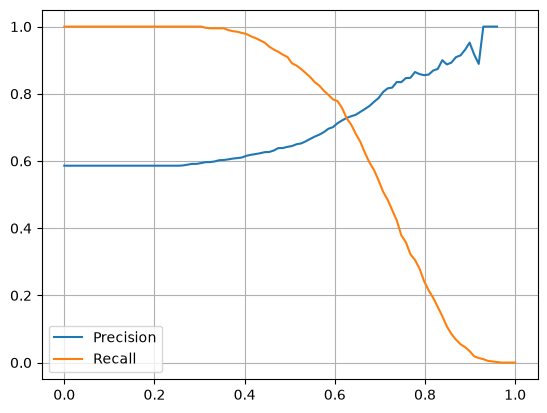

In [96]:
plt.plot(df_pr.thr, df_pr['precision'], label='Precision')
plt.plot(df_pr.thr, df_pr['recall'], label='Recall')
plt.grid(True)
plt.legend()

In [97]:
print(f"[ANSWER-3] Precision and Recall curves intersect at thr == 0.63 (aproximately)")

[ANSWER-3] Precision and Recall curves intersect at thr == 0.63 (aproximately)


Question 4: F1 score


In [98]:
df_pr["f1_score"] = 2 * (df_pr["precision"] * df_pr["recall"])/(df_pr["precision"] + df_pr["recall"])

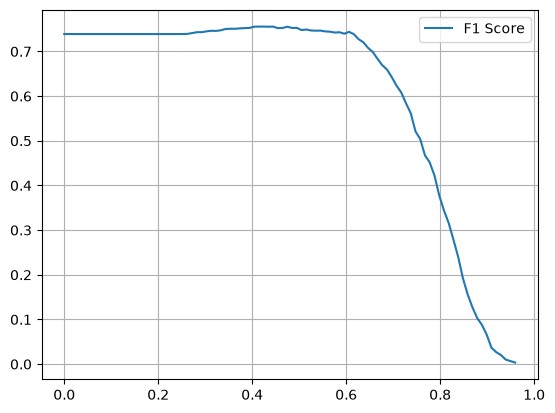

In [99]:
plt.plot(df_pr.thr, df_pr['f1_score'], label='F1 Score')
plt.grid(True)
plt.legend()

In [100]:
print(f"[ANSWER-4] F1 Score has max value at thr == 0.41 (aproximately)")

[ANSWER-4] F1 Score has max value at thr == 0.41 (aproximately)


Question 5: 5-Fold CV

In [101]:
df_full_train[feat_list].columns

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score'],
      dtype='str')

In [102]:
feat_list

['lead_source',
 'industry',
 'employment_status',
 'location',
 'annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

In [103]:
scores = []
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

for train_idx, val_idx in kfold.split(df_full_train): 
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    dv, model = train(df_train, df_train.converted, feat_list=feat_list)
    y_pred = predict(df_val, dv, model, feat_list=feat_list)

    auc = roc_auc_score(df_val.converted, y_pred)
    scores.append(auc)

print(' %.3f +- %.3f' % (np.mean(scores), np.std(scores)))


 0.732 +- 0.007


In [104]:
print(f"[ANSWER-5] The standard deviation is: 0.007")

[ANSWER-5] The standard deviation is: 0.007


Question 6: Hyperparameter Tuning

In [105]:
for C in (0.000001, 0.001, 1):
    scores = []
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)

    for train_idx, val_idx in kfold.split(df_full_train): 
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        dv, model = train(df_train, df_train.converted, feat_list=feat_list, C=C)
        y_pred = predict(df_val, dv, model, feat_list=feat_list)

        auc = roc_auc_score(df_val.converted, y_pred)
        scores.append(auc)
    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))     

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007


In [106]:
print(f"[ANSWER-6] C=0.001 leads the best mean score (0.749)")

[ANSWER-6] C=0.001 leads the best mean score (0.749)
